In [1]:
123

123


# FineWeb2 Georgian — Exploratory Data Analysis

## Цель

Исследовать корпус FineWeb2 `kat_Geor`, предназначенный для обучения небольшой decoder-only языковой модели GeorgiaGPT.

Анализ проводится в двух режимах:

- `sample`: диагностическая равномерная выборка из 10 000 документов;
- `full`: весь обучающий корпус FineWeb2.

Оба режима используют один вычислительный пайплайн.

## Принципы

- Исходные документы не изменяются.
- Учитывается предварительная фильтрация, выполненная авторами FineWeb2.
- Вычисление метрик отделено от их визуализации.
- Результаты сохраняются для повторного исследования без перерасчёта.
- Дополнительная очистка не применяется без подтверждённой необходимости.


In [22]:

import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyarrow.parquet as pq

from IPython.display import display

from ggpt.analysis.full_eda import run_full_eda


PROJECT_ROOT = next(
    (
        path
        for path in (Path.cwd(), *Path.cwd().parents)
        if (path / "src" / "ggpt").is_dir()
    ),
    None,
)

if PROJECT_ROOT is None:
    raise RuntimeError("GGPT project root not found")

src_path = str(PROJECT_ROOT / "src")

if src_path not in sys.path:
    sys.path.insert(0, src_path)

from ggpt.analysis.eda import run_eda
from ggpt.data.parquet_corpus import ParquetCorpus

print("Project root:", PROJECT_ROOT)
print("Python executable:", sys.executable)


Project root: /home/daneque/projects/GGPT
Python executable: /home/daneque/miniconda/envs/ggpt/bin/python


In [26]:

MODE = "full"

BATCH_SIZE = 512
RUN_EDA = True
ALLOW_FULL_EDA = True

MAX_NEW_PARTS = None

SAMPLE_DIR = (
    PROJECT_ROOT
    / "data/samples/fineweb2/kat_Geor/train/n10000_seed42"
)

FULL_DIR = (
    PROJECT_ROOT
    / "data/raw/fineweb2/data/kat_Geor/train"
)

RAW_MANIFEST_PATH = (
    PROJECT_ROOT
    / "data/raw/fineweb2/download_manifest.json"
)

RESULTS_ROOT = PROJECT_ROOT / "data/interim/eda"

RESULT_DIRS = {
    "sample": RESULTS_ROOT / "sample_n10000_seed42",
    "full": RESULTS_ROOT / "full_train",
}

if MODE not in RESULT_DIRS:
    raise ValueError(f"Unsupported mode: {MODE}")

SOURCE_DIR = SAMPLE_DIR if MODE == "sample" else FULL_DIR
RESULT_DIR = RESULT_DIRS[MODE]

METRICS_PATH = RESULT_DIR / "metrics.parquet"
SUMMARY_PATH = RESULT_DIR / "summary.json"
EDA_MANIFEST_PATH = RESULT_DIR / "manifest.json"

with RAW_MANIFEST_PATH.open(encoding="utf-8") as f:
    raw_manifest = json.load(f)

DATASET_REVISION = raw_manifest["revision"]

print("Mode:", MODE)
print("Source:", SOURCE_DIR)
print("Results:", RESULT_DIR)
print("FineWeb2 revision:", DATASET_REVISION)


Mode: full
Source: /home/daneque/projects/GGPT/data/raw/fineweb2/data/kat_Geor/train
Results: /home/daneque/projects/GGPT/data/interim/eda/full_train
FineWeb2 revision: af9c13333eb981300149d5ca60a8e9d659b276b9


In [27]:

if not SOURCE_DIR.is_dir():
    raise FileNotFoundError(SOURCE_DIR)

corpus = ParquetCorpus(SOURCE_DIR)

print(f"Documents: {corpus.total_documents:,}")
print(f"Parquet files: {len(corpus.files)}")

if MODE == "sample":
    sample_manifest_path = SAMPLE_DIR / "manifest.json"

    with sample_manifest_path.open(encoding="utf-8") as f:
        sample_manifest = json.load(f)

    assert (
        corpus.total_documents
        == sample_manifest["sample_documents"]
    )

    assert (
        sample_manifest["revision"]
        == DATASET_REVISION
    )

    print("Sampling method:", sample_manifest["method"])
    print("Sampling seed:", sample_manifest["seed"])

else:
    assert corpus.total_documents == 3_706_659

print("Source validation: OK")


Documents: 3,706,659
Parquet files: 2
Source validation: OK


In [28]:

if EDA_MANIFEST_PATH.exists():
    manifest = json.loads(
        EDA_MANIFEST_PATH.read_text(encoding="utf-8")
    )

    if manifest["status"] != "complete":
        raise RuntimeError("Existing EDA is incomplete")

    print("Using completed EDA results")

elif RUN_EDA:
    if MODE == "full":
        if not ALLOW_FULL_EDA:
            raise RuntimeError("Full EDA is disabled")

        result = run_full_eda(
            source_dir=SOURCE_DIR,
            output_dir=RESULT_DIR,
            dataset_revision=DATASET_REVISION,
            batch_size=BATCH_SIZE,
            row_groups_per_part=100,
            max_new_parts=MAX_NEW_PARTS,
        )

    else:
        result = run_eda(
            source_dir=SOURCE_DIR,
            output_dir=RESULT_DIR,
            mode=MODE,
            batch_size=BATCH_SIZE,
            show_progress=True,
            dataset_revision=DATASET_REVISION,
        )

    print(result)

else:
    raise FileNotFoundError(
        f"No completed EDA found in {RESULT_DIR}"
    )


Part 2/38: 100%|██████████| 100000/100000 [03:17<00:00, 505.82docs/s]


Saved checkpoint 2/38: 100,000 rows


Part 3/38: 100%|██████████| 100000/100000 [03:07<00:00, 534.41docs/s]


Saved checkpoint 3/38: 100,000 rows


Part 4/38: 100%|██████████| 100000/100000 [03:09<00:00, 528.64docs/s]


Saved checkpoint 4/38: 100,000 rows


... (64 outputs left out)

Part 37/38: 100%|██████████| 100000/100000 [02:58<00:00, 560.43docs/s]


Saved checkpoint 37/38: 100,000 rows


Part 38/38: 100%|██████████| 72659/72659 [02:08<00:00, 564.69docs/s]


Saved checkpoint 38/38: 72,659 rows
{'status': 'complete', 'documents': 3706659, 'metrics_path': PosixPath('/home/daneque/projects/GGPT/data/interim/eda/full_train/metrics.parquet'), 'summary_path': PosixPath('/home/daneque/projects/GGPT/data/interim/eda/full_train/summary.json'), 'manifest_path': PosixPath('/home/daneque/projects/GGPT/data/interim/eda/full_train/manifest.json')}


In [29]:

with SUMMARY_PATH.open(encoding="utf-8") as f:
    summary = json.load(f)

with EDA_MANIFEST_PATH.open(encoding="utf-8") as f:
    eda_manifest = json.load(f)

total_documents = summary["total_documents"]
saved_documents = pq.read_metadata(METRICS_PATH).num_rows

assert eda_manifest["status"] == "complete"
assert eda_manifest["mode"] == MODE
assert eda_manifest["dataset_revision"] == DATASET_REVISION
assert total_documents == corpus.total_documents
assert saved_documents == total_documents

print(f"Analyzed documents: {total_documents:,}")
print(f"Saved metric rows: {saved_documents:,}")
print(f"Elapsed: {eda_manifest['elapsed_seconds']:.2f} s")

display(
    pd.DataFrame(
        summary["stage_timings_seconds"].items(),
        columns=["stage", "seconds"],
    )
)


Analyzed documents: 3,706,659
Saved metric rows: 3,706,659
Elapsed: 6424.84 s


,stage,seconds
0,reading,177.828
1,profiling,6223.128
2,aggregation,13.042
3,writing,73.990


In [30]:

numeric_summary = (
    pd.DataFrame(summary["numeric"])
    .set_index("metric")
)

flag_summary = (
    pd.DataFrame(summary["flags"])
    .set_index("flag")
)

important_metrics = [
    "n_words",
    "n_chars",
    "n_bytes",
    "georgian_share",
    "latin_share",
    "cyrillic_share",
    "repeated_line_share",
]

display(
    numeric_summary.loc[
        important_metrics,
        ["count", "mean", "std", "min", "max"],
    ].round(4)
)

display(flag_summary)


,count,mean,std,min,max
metric,,,,,
n_words,3706659,330.5774,748.3454,40.0000,6.472300e+04
n_chars,3706659,2771.0006,5948.1571,245.0000,4.072250e+05
n_bytes,3706659,7309.6808,15566.4752,421.0000,1.038919e+06
georgian_share,3706659,0.9725,0.0724,0.1907,1.000000e+00
latin_share,3706659,0.0263,0.0695,0.0000,7.563000e-01
cyrillic_share,3706659,0.0009,0.0156,0.0000,6.588000e-01
repeated_line_share,3706659,0.0081,0.0345,0.0000,3.864000e-01


,documents,share
flag,,
is_missing_text,0,0.000000
is_empty_text,0,0.000000
has_html_like,1799,0.000485


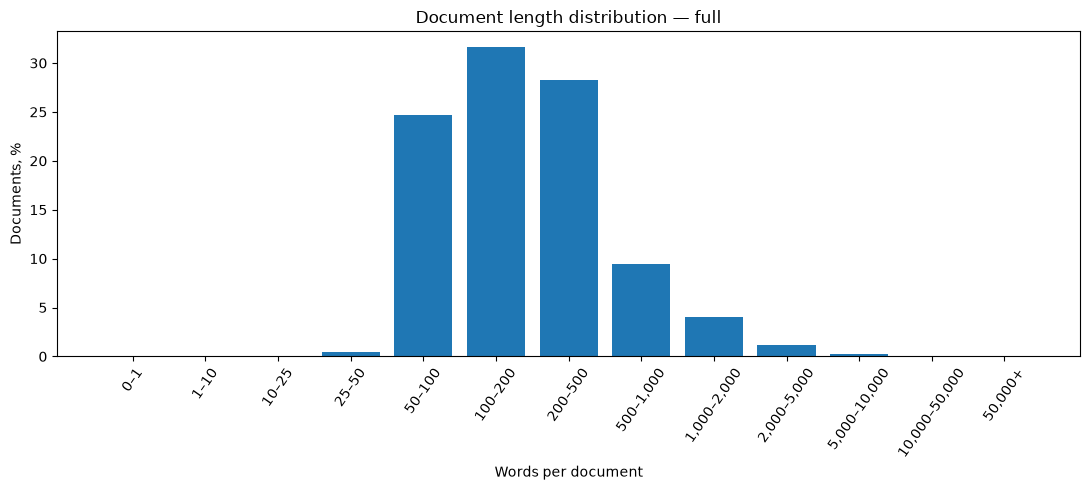

In [31]:

word_hist = pd.DataFrame(
    summary["histograms"]["n_words"]
)

labels = [
    f"{int(left):,}–{int(right):,}"
    if right != "+inf"
    else f"{int(left):,}+"
    for left, right in zip(
        word_hist["left"],
        word_hist["right"],
    )
]

percentages = (
    100 * word_hist["documents"] / total_documents
)

fig, ax = plt.subplots(figsize=(11, 5))

ax.bar(labels, percentages)

ax.set_title(
    f"Document length distribution — {MODE}"
)
ax.set_xlabel("Words per document")
ax.set_ylabel("Documents, %")

ax.tick_params(axis="x", rotation=55)

plt.tight_layout()
plt.show()


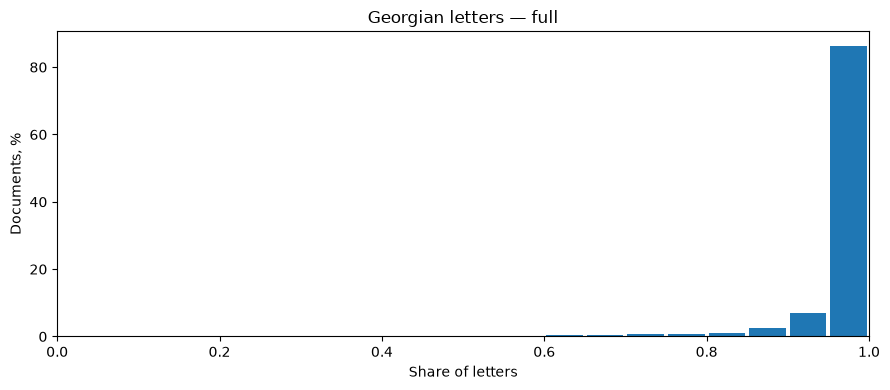

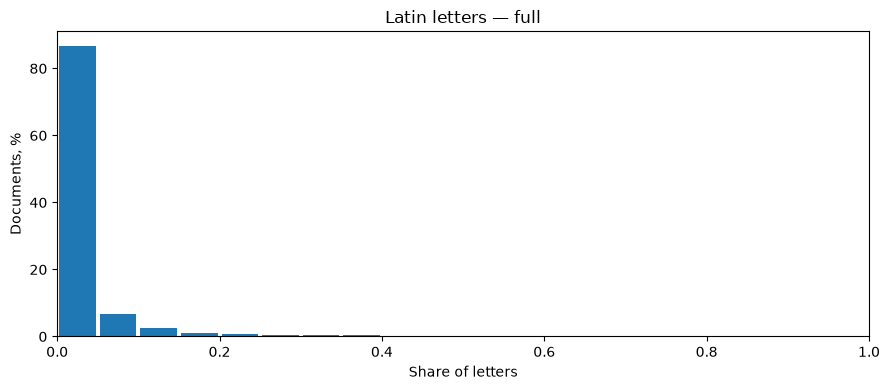

In [32]:

script_metrics = {
    "georgian_share": "Georgian letters",
    "latin_share": "Latin letters",
    "cyrillic_share": "Cyrillic letters",
}

for metric, title in script_metrics.items():
    if metric not in summary["histograms"]:
        continue

    histogram = pd.DataFrame(
        summary["histograms"][metric]
    )

    centers = (
        histogram["left"] + histogram["right"]
    ) / 2

    percentages = (
        histogram["documents"] / total_documents * 100
    )

    fig, ax = plt.subplots(figsize=(9, 4))

    ax.bar(
        centers,
        percentages,
        width=0.045,
    )

    ax.set_title(f"{title} — {MODE}")
    ax.set_xlabel("Share of letters")
    ax.set_ylabel("Documents, %")
    ax.set_xlim(0, 1)

    plt.tight_layout()
    plt.show()


In [33]:

quantile_columns = [
    "n_words",
    "n_chars",
    "georgian_share",
    "latin_share",
    "repeated_line_share",
]

quantile_levels = [
    0.01,
    0.10,
    0.25,
    0.50,
    0.75,
    0.90,
    0.99,
]

quantiles = {}

for column in quantile_columns:
    values = pd.read_parquet(
        METRICS_PATH,
        columns=[column],
    )[column]

    quantiles[column] = values.quantile(
        quantile_levels
    )

    del values

quantile_table = pd.DataFrame(quantiles)

display(quantile_table.round(4))


,n_words,n_chars,georgian_share,latin_share,repeated_line_share
0.01,51.0,429.0,0.5847,0.0000,0.0
0.10,69.0,598.0,0.9302,0.0000,0.0
0.25,99.0,855.0,0.9792,0.0000,0.0
0.50,170.0,1462.0,0.9980,0.0018,0.0
0.75,330.0,2797.0,1.0000,0.0201,0.0
0.90,675.0,5631.0,1.0000,0.0673,0.0
0.99,2429.0,20052.0,1.0000,0.3909,0.2


In [34]:

from collections import Counter


METADATA_SUMMARY_PATH = RESULT_DIR / "metadata_summary.json"

if METADATA_SUMMARY_PATH.exists():
    metadata_summary = json.loads(
        METADATA_SUMMARY_PATH.read_text(encoding="utf-8")
    )

else:
    score_edges = np.linspace(0, 1, 21)
    cluster_edges = np.array(
        [0, 1, 2, 3, 5, 10, 20, 50, 100, 1000, np.inf],
        dtype=float,
    )

    score_counts = np.zeros(20, dtype=np.int64)
    cluster_counts = np.zeros(10, dtype=np.int64)

    dump_counts = Counter()
    year_counts = Counter()

    rows_scanned = 0

    parquet_file = pq.ParquetFile(METRICS_PATH)

    for record_batch in parquet_file.iter_batches(
        batch_size=16_384,
        columns=[
            "language_score",
            "minhash_cluster_size",
            "dump",
            "date",
        ],
    ):
        frame = record_batch.to_pandas()
        rows_scanned += len(frame)

        scores = pd.to_numeric(
            frame["language_score"],
            errors="coerce",
        ).to_numpy(dtype=float, na_value=np.nan)

        scores = scores[np.isfinite(scores)]

        score_counts += np.histogram(
            np.clip(scores, 0.0, 1.0),
            bins=score_edges,
        )[0]

        cluster_sizes = pd.to_numeric(
            frame["minhash_cluster_size"],
            errors="coerce",
        ).to_numpy(dtype=float, na_value=np.nan)

        cluster_sizes = cluster_sizes[
            np.isfinite(cluster_sizes)
        ]

        cluster_counts += np.histogram(
            cluster_sizes,
            bins=cluster_edges,
        )[0]

        dump_counts.update(
            frame["dump"].dropna().astype(str)
        )

        years = pd.to_numeric(
            frame["date"].astype("string").str.slice(0, 4),
            errors="coerce",
        )

        years = years[years.between(1990, 2100)]

        year_counts.update(
            years.dropna().astype(int)
        )

    assert rows_scanned == total_documents

    metadata_summary = {
        "total_documents": rows_scanned,
        "score_edges": score_edges.tolist(),
        "score_counts": score_counts.tolist(),
        "cluster_edges": [
            "+inf" if np.isinf(value) else int(value)
            for value in cluster_edges
        ],
        "cluster_counts": cluster_counts.tolist(),
        "dump_counts": dict(dump_counts),
        "year_counts": {
            str(year): int(count)
            for year, count in year_counts.items()
        },
    }

    temporary_path = METADATA_SUMMARY_PATH.with_name(
        "metadata_summary.json.partial"
    )

    temporary_path.write_text(
        json.dumps(
            metadata_summary,
            ensure_ascii=False,
            indent=2,
        ),
        encoding="utf-8",
    )

    temporary_path.replace(METADATA_SUMMARY_PATH)

print("Metadata documents:", metadata_summary["total_documents"])
print("Metadata summary:", METADATA_SUMMARY_PATH)


Metadata documents: 3706659
Metadata summary: /home/daneque/projects/GGPT/data/interim/eda/full_train/metadata_summary.json


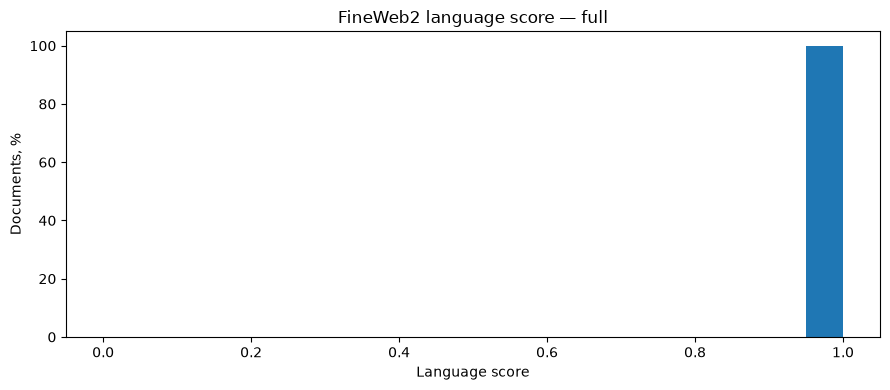

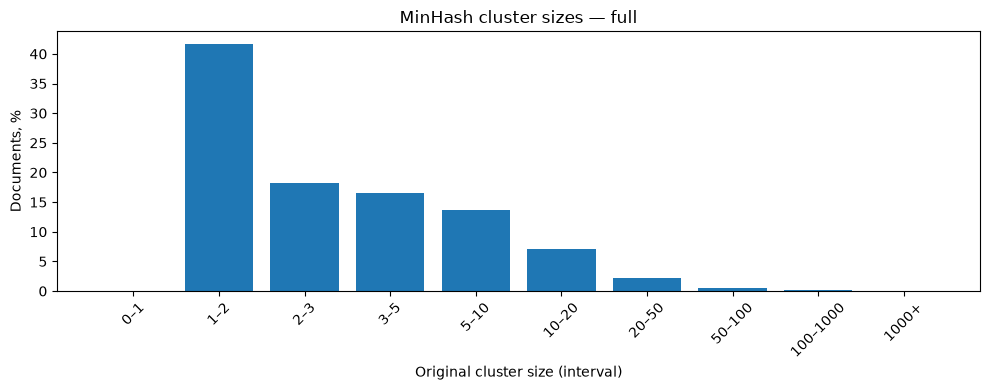

,documents
dump,
CC-MAIN-2023-50,135746
CC-MAIN-2023-40,131379
CC-MAIN-2024-18,101609
CC-MAIN-2024-10,101192
CC-MAIN-2023-14,100484
CC-MAIN-2023-23,99245
CC-MAIN-2020-24,97623
CC-MAIN-2022-49,97437
CC-MAIN-2021-49,96274


In [35]:

score_edges = metadata_summary["score_edges"]
score_counts = np.array(metadata_summary["score_counts"])

fig, ax = plt.subplots(figsize=(9, 4))

ax.bar(
    score_edges[:-1],
    100 * score_counts / total_documents,
    width=np.diff(score_edges),
    align="edge",
)

ax.set_title(f"FineWeb2 language score — {MODE}")
ax.set_xlabel("Language score")
ax.set_ylabel("Documents, %")

plt.tight_layout()
plt.show()


cluster_edges = metadata_summary["cluster_edges"]
cluster_counts = metadata_summary["cluster_counts"]

cluster_labels = [
    f"{left}–{right}"
    if right != "+inf"
    else f"{left}+"
    for left, right in zip(
        cluster_edges[:-1],
        cluster_edges[1:],
    )
]

fig, ax = plt.subplots(figsize=(10, 4))

ax.bar(
    cluster_labels,
    100 * np.array(cluster_counts) / total_documents,
)

ax.set_title(f"MinHash cluster sizes — {MODE}")
ax.set_xlabel("Original cluster size (interval)")
ax.set_ylabel("Documents, %")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


dump_table = (
    pd.Series(metadata_summary["dump_counts"], name="documents")
    .sort_values(ascending=False)
    .rename_axis("dump")
    .to_frame()
)

display(dump_table.head(20))


In [36]:

SAMPLE_METRICS_PATH = (
    RESULT_DIRS["sample"] / "metrics.parquet"
)

if not SAMPLE_METRICS_PATH.exists():
    raise FileNotFoundError(
        "Run EDA in sample mode before manual review"
    )

sample_texts = pd.read_parquet(
    SAMPLE_DIR / "sample.parquet",
    columns=[
        "_global_row",
        "id",
        "url",
        "text",
        "language_score",
        "minhash_cluster_size",
    ],
)

sample_metrics = pd.read_parquet(
    SAMPLE_METRICS_PATH,
    columns=[
        "_global_row",
        "n_words",
        "n_chars",
        "georgian_share",
        "latin_share",
        "repeated_line_share",
    ],
)

review_data = sample_texts.merge(
    sample_metrics,
    on="_global_row",
    validate="one_to_one",
)

candidates = pd.concat(
    [
        review_data.sample(n=20, random_state=42),
        review_data.nsmallest(10, "georgian_share"),
        review_data.nlargest(10, "latin_share"),
        review_data.nlargest(10, "repeated_line_share"),
        review_data.nlargest(10, "n_words"),
        review_data.nlargest(10, "minhash_cluster_size"),
        review_data.nsmallest(10, "language_score"),
    ],
    ignore_index=True,
).drop_duplicates(subset=["_global_row"])

print(f"Review candidates: {len(candidates)}")

preview = candidates.assign(
    text_preview=candidates["text"].fillna("").str.slice(0, 250)
).drop(columns=["text"])

display(preview.head(20))


Review candidates: 67


,_global_row,id,url,language_score,minhash_cluster_size,n_words,n_chars,georgian_share,latin_share,repeated_line_share,text_preview
0,2283589,<urn:uuid:ba1bcad3-1674-44f9-9f76-cfdac4aac666>,http://bfm.ge/?p=36304,0.999855,3,80,706,1.000000,0.000000,0.0,ბიზნესმენი თემურ ჭყონია „საქმის კურსთან“ მთავრ...
1,1716017,<urn:uuid:7069ca3e-d2f0-40f3-a2f0-61e42eae9e62>,https://popmusic.ge/article/9879-nakhet-rich-b...,0.999912,10,85,704,0.844178,0.155822,0.0,ახალგაზრდა ინდონეზიელმა რეპერმა ბრაიან იმანუელ...
2,640697,<urn:uuid:fa8a5645-b60b-4a19-a166-6dbde85ee7c5>,https://isurve.ge/collections/boshis-gamwovi,0.999991,4,370,2904,0.993001,0.006999,0.0,"ბოშის გამწოვი\nბოშის გამწოვი, გერმანული სამზარ..."
3,1734839,<urn:uuid:e9e4c57b-327e-495a-84ac-54e0ca421d85>,https://everydaygeorgia.ge/2019/12/25/4835/,1.000002,3,306,2331,1.000000,0.000000,0.0,"საქართველოს პრეზიდენტმა, სალომე ზურაბიშვილმა ს..."
4,1658838,<urn:uuid:28b64754-bee3-4144-9fed-7c7025369e22>,http://ghn.ge/index.php/news/235097-italiis-sk...,0.999998,7,135,1216,1.000000,0.000000,0.0,"2020 წლიდან იტალია გახდება პირველი ქვეყანა, სა..."
5,2318783,<urn:uuid:e1fe7b46-77b8-4987-99a3-889302edc67f>,https://fanebi.com/kaka-milanis-phekhburtheleb...,0.999956,2,100,815,0.998507,0.000000,0.0,კაკა: „მილანის“ ფეხბურთელებმა სიტუაცია თავადვე...
6,223202,<urn:uuid:6ae2c6a0-2c48-489f-8d72-d233f188dea4>,https://www.amerikiskhma.com/a/a-54-2009-11-07...,1.000002,2,60,493,1.000000,0.000000,0.0,გაეროს გენერალურმა მდივანმა ბან კი მუნმა განაც...
7,1902688,<urn:uuid:273375a3-1994-4a86-8007-6ab9bc753a6b>,https://commersant.ge/ge/post/saqartveloshi-tu...,0.999968,1,291,2528,0.995347,0.004653,0.0,თბილისში სასტუმროებისა და ტურიზმის მენეჯმენტის...
8,2326918,<urn:uuid:69cb1319-1e6a-43da-8b7e-ed59dc72374e>,https://mykadri.com/slide/page/8/,0.999929,1,461,3929,0.998760,0.001240,0.0,"2019\nსერიალი, .., ფილმები ზომბებზე ქართულად\n..."
9,168205,<urn:uuid:cc067c7a-b57e-4a65-acc5-63359ec481c9>,https://guria.tv/%E1%83%99%E1%83%A3%E1%83%9A%E...,0.999885,1,267,2530,0.996817,0.003183,0.0,საქართველოს კულტურის სამინისტრო მუშაობს კანონპ...


In [15]:

REVIEW_PATH = (
    RESULT_DIRS["sample"] / "review_candidates.jsonl"
)

candidates.to_json(
    REVIEW_PATH,
    orient="records",
    lines=True,
    force_ascii=False,
)

print("Saved review candidates:", REVIEW_PATH)
print("Documents:", len(candidates))


Saved review candidates: /home/daneque/projects/GGPT/data/interim/eda/sample_n10000_seed42/review_candidates.jsonl
Documents: 67


In [37]:

sample_summary_path = (
    RESULT_DIRS["sample"] / "summary.json"
)

full_summary_path = (
    RESULT_DIRS["full"] / "summary.json"
)

if sample_summary_path.exists() and full_summary_path.exists():
    sample_summary = json.loads(
        sample_summary_path.read_text(encoding="utf-8")
    )

    full_summary = json.loads(
        full_summary_path.read_text(encoding="utf-8")
    )

    sample_numeric = (
        pd.DataFrame(sample_summary["numeric"])
        .set_index("metric")
    )

    full_numeric = (
        pd.DataFrame(full_summary["numeric"])
        .set_index("metric")
    )

    comparison = pd.DataFrame({
        "sample_mean": sample_numeric["mean"],
        "full_mean": full_numeric["mean"],
    })

    comparison["difference"] = (
        comparison["sample_mean"]
        - comparison["full_mean"]
    )

    display(
        comparison.loc[
            important_metrics
        ].round(4)
    )

else:
    print(
        "Full EDA is not available yet. "
        "Comparison will be enabled after the full run."
    )


,sample_mean,full_mean,difference
metric,,,
n_words,329.5907,330.5774,-0.9867
n_chars,2760.0407,2771.0006,-10.9599
n_bytes,7285.0292,7309.6808,-24.6516
georgian_share,0.9728,0.9725,0.0003
latin_share,0.0264,0.0263,0.0001
cyrillic_share,0.0007,0.0009,-0.0003
repeated_line_share,0.0079,0.0081,-0.0002
